[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yassirtl/LangGraph-Lab/blob/main/langgraph_lab.ipynb)

# Practical Lab — Building AI Agents with LangGraph

**Course:** Advanced Artificial Intelligence / Generative AI
**Attendees** PHD Students.
**Technology:** Python, LangChain, LangGraph, LLM APIs  
**Level:** Intermediate | **Format:** Jupyter Notebook

## 1. Lab objectives

At the end of this lab, you should be able to:

- Explain the difference between a conventional LLM chain and an agentic workflow.
- Understand the main LangGraph concepts: **State, Nodes, Edges, Conditional edges, Graph execution**.
- Build a simple conversational agent and add memory/state to it.
- Implement conditional routing and integrate tools.
- Build a multi-step research-style agent that can decide which action to perform.
- Visualize and test the resulting graph, and evaluate its behavior.

> **Tip:** Write your answers to the conceptual questions in the *"Answer"* cells. They form part of your final report.

## PART I — Environment setup
### Exercise 1 — Install LangGraph

In [1]:
!pip install -U langgraph langchain langchain-openai langchain-community

In [2]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.19
LangChain: 1.4.7


### Question
What is the role of:
1. **LangChain?**
2. **LangGraph?**
3. **An LLM?**

**Answer:**  
1. **LangChain** is a framework of building blocks for LLM applications: a common interface to many model providers (`ChatOpenAI`, ...), prompts, message types, tools, retrievers and output parsers. It is good at linear pipelines (chains) where the steps are fixed in advance.  
2. **LangGraph** is built on top of LangChain and models an application as a **graph**: nodes (Python functions) that read and update a shared **state**, connected by edges that can be **conditional** and can form **loops**. It also adds persistence (checkpointers), so it is suited to agents that decide at runtime what to do next, call tools repeatedly and keep memory.  
3. **An LLM** (large language model) is the neural network that generates text from a prompt, e.g. `gpt-4o-mini`. In the agent it is the reasoning component: it understands the question, classifies it, decides whether a tool is needed and writes the answer. LangChain/LangGraph only orchestrate around it.

## PART II — First LangGraph workflow
### Exercise 2 — Understanding State

In LangGraph, the **state** represents the information shared between nodes.

In [3]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [4]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [5]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [6]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


**Expected result**
```python
{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}
```

### Questions
1. What is a node?
2. What is an edge?
3. What is `START`?
4. What is `END`?
5. Why is the state passed between nodes?

**Answer:**  
1. A **node** is a unit of work: a Python function that receives the current state and returns a dictionary with the keys it wants to update (here `process_message` returns `{"response": ...}`).  
2. An **edge** defines which node runs after another. A normal edge is fixed (`process` → `END`); a conditional edge chooses the next node at runtime from a routing function.  
3. `START` is the virtual entry point of the graph. The edge `START → process` says which node runs first when `invoke` is called.  
4. `END` is the virtual exit point. When execution reaches it, the graph stops and `invoke` returns the final state.  
5. The state is the only shared memory between nodes: each node reads what previous nodes produced and adds its own result. This keeps nodes independent and reusable, makes the data flow explicit and inspectable, and is what allows checkpointing (saving and resuming the state) and memory.

## PART III — Building an LLM Agent
### Exercise 3 — Connect an LLM

**Do not hard-code the API key in the notebook.** Prefer an environment variable configured outside the notebook; otherwise prompt for it securely as below.

In [7]:
import os
from getpass import getpass
from langchain_openai import ChatOpenAI

if not os.environ.get("OPENAI_API_KEY"):
    try:
        # Colab: add OPENAI_API_KEY in the Secrets panel (key icon on the left)
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")

llm = ChatOpenAI(
    model="gpt-4o-mini", # or other model
    temperature=0
)

print(llm.invoke("Say hello in one short sentence.").content)

Hello!


### Exercise 4 — Create an LLM node

In [8]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.content}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [9]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

Artificial intelligence (AI) refers to the simulation of human intelligence processes by machines, particularly computer systems. These processes include learning, reasoning, problem-solving, perception, and language understanding. AI can be categorized into narrow AI, which is designed for specific tasks, and general AI, which aims to perform any intellectual task that a human can do.


## PART IV — Multi-node AI workflow
### Exercise 5 — Build a two-stage agent

```
User question → Question analyzer → Answer generator → Final answer
```

In [10]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.content}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.content}

In [11]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [12]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

Reinforcement learning (RL) is a subfield of machine learning that focuses on how agents should take actions in an environment to maximize cumulative rewards over time. It is based on the idea of learning through interaction, where an agent learns to make decisions by receiving feedback in the form of rewards or penalties.

### Key Concepts:

1. **Agent**: The learner or decision-maker that interacts with the environment.
2. **Environment**: The external system with which the agent interacts. It provides feedback based on the agent's actions.
3. **Actions**: The choices made by the agent that affect the state of the environment.
4. **States**: The current situation or configuration of the environment that the agent observes.
5. **Rewards**: Feedback signals received by the agent after taking an action, indicating the immediate benefit of that action.
6. **Policy**: A strategy used by the agent to determine its actions based on the current state. It can be deterministic or stochastic.



## PART V — Conditional routing

This is where LangGraph becomes particularly interesting. The agent decides which branch to follow:

```
                 ┌─── Mathematics
Question ────────┼─── Programming
                 └─── General AI
```

### Exercise 6 — Create a router

In [13]:
class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.content.strip().lower()}

### Exercise 7 — Create specialized nodes

In [14]:
def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.content}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.content}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.content}

## PART VI — Conditional edges

The routing function inspects the state and returns the **name of the next branch**.

In [15]:
def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"   # default / fallback branch

In [16]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [17]:
questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })
    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: The derivative of \( x^2 \) with respect to \( x \) is calculated using the power rule. According to the power rule, if \( f(x) = x^n \), then \( f'(x) = n \cdot x^{n-1} \).

For \( f(x) = x^2 \):

1. Identify \( n = 2 \).
2. Apply the power rule: 
   \[
   f'(x) = 2 \cdot x^{2-1} = 2x^1 = 2x.
   \]

Therefore, the derivative of \( x^2 \) is \( 2x \).
QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: Creating a REST API with Python can be accomplished using various frameworks, but one of the most popular and user-friendly options is Flask. Below, I'll guide you through the steps to create a simple REST API using Flask.

### Step 1: Install Flask

First, you need to install Flask. You can do this using pip. Open your terminal and run:

```bash
pip install Flask
```

### Step 2: Create a Basic Flask Application

Create a new Python file, for example, `app.py`, and add the following code to

## PART VII — Agent with tools
### Exercise 8 — Create tools

The original lab uses `eval()`, which is **dangerous** (it can execute arbitrary Python). Below we first show the lab version for comparison, then a **safe** calculator built on `ast` that only allows arithmetic. We use the safe one from here on.

In [18]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [19]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [20]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Saturday, 31 October 2026, 09:02:03


## PART VIII — Tool-using agent

```
                 ┌─────────────┐
Question → Agent ├→ Calculator │
                 └─────────────┘
                       ↓
                    Answer
```

The agent must **decide** whether it needs the calculator. Expected behavior for *"What is 125 * 38?"*:

`Agent → recognizes math problem → calls calculator → receives result → generates answer`

We bind the tools to the LLM, so it can emit *tool calls*. A conditional edge sends the flow to the `tools` node when a tool call is present, then loops back to the agent.

In [21]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime]
llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_builder = StateGraph(MessagesState)
tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)  # -> "tools" or END
tool_builder.add_edge("tools", "agent")                       # loop back with the result

tool_graph = tool_builder.compile()

In [22]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================
Tool Calls:
  calculator (call_OQWrWGfOKLtSvWmk2QGOsMG4)
 Call ID: call_OQWrWGfOKLtSvWmk2QGOsMG4
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

The result of \( 125 \times 38 \) is 4750.
Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

The capital of Morocco is Rabat.


**Observe:** for the first question the trace contains an `AIMessage` with a tool call, a `ToolMessage` with the result, then the final answer. For the second question, no tool is called.

## PART IX — Memory
### Exercise 9 — Conversational state

The `add_messages` reducer **appends** new messages to the list instead of overwriting it.

In [23]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

**Without a checkpointer**, each `invoke` starts from scratch. **With a checkpointer** (`MemorySaver`) and a `thread_id`, the conversation persists between calls.

In [24]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

WITHOUT memory: I'm sorry, but I don't have access to personal information about you unless you share it with me. How can I assist you today?


In [25]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

Agent: Nice to meet you, Ahmed! How can I assist you today?
Agent: Your name is Ahmed. How can I help you today?
Other thread: I'm sorry, but I don't have access to personal information about individuals unless it has been shared with me in the course of our conversation. If you'd like to share your name or any other details, feel free to do so!


## Visualizing and testing graphs

`get_graph()` returns a drawable representation. If PNG rendering is unavailable (it may need network access), print the Mermaid source and paste it into <https://mermaid.live>.

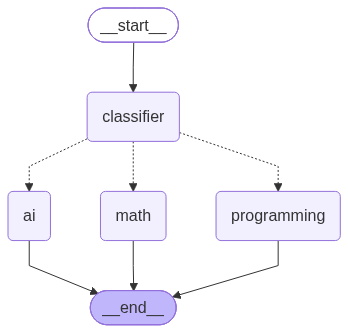

PNG rendering unavailable: Failed to reach https://mermaid.ink API while trying to render your graph. Status code: 400.

To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools<hr/><small><em>__tools = ['calculator', 'current_datetime']</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	tools --> agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [26]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

## Evaluating the behavior of an agentic workflow

A minimal evaluation harness: define test cases with expected categories, run them, and compute accuracy. You can extend this with tool-call checks, latency, and cost.

In [27]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,2.24
1,Solve 2x + 3 = 11,mathematics,mathematics,True,2.00
2,How do I reverse a list in Python?,programming,programming,True,4.34
3,Write a function to check for palindromes.,programming,programming,True,4.32
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,6.56
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,7.59


Routing accuracy: 6/6 = 100%


**Discussion:** Where did the router fail (if anywhere)? What would make the routing more robust (structured output, few-shot examples, enum validation)?

**Answer:** In our run the router made no mistake (6/6 = 100%, plus 3/3 in the Part VI demo), but the test set is small and the questions are unambiguous. The router relies on the LLM returning a free-text label, then on a substring check (`"mathematics" in category`). Possible failure causes are ambiguous questions (e.g. *"Write a Python function to compute a derivative"* is both programming and mathematics), from the model adding extra words or a different spelling (`"Mathematics."`, `"AI"`, `"math"`), and from the silent fallback to `ai`, which hides misclassifications. To make it more robust:  
- **Structured output** (`llm.with_structured_output(...)` with a Pydantic model or `Literal["mathematics", "programming", "artificial_intelligence"]`), so the model can only return a valid category.  
- **Enum validation** of the returned label, and logging when the fallback is used instead of hiding it.  
- **Few-shot examples** in the prompt, especially for borderline cases, and `temperature=0` (already used) for deterministic answers.  
- A larger labelled test set to measure accuracy per category (confusion matrix), not only on 6 questions.

## PART X — Capstone project: Intelligent University Assistant

### Requirements covered below
| # | Requirement | Implementation |
|---|---|---|
| 1 | Question classifier | `classify` node → COURSES / PROGRAMMING / MATHEMATICS / ADMINISTRATION / GENERAL |
| 2 | Specialized agents | one node per category, built with `make_agent` |
| 3 | Memory | `MemorySaver` checkpointer + `thread_id` |
| 4 | Tools | `calculator`, `current_datetime` (+ optional extras) |
| 5 | Conditional routing | `route_after_classifier`, `route_after_agent`, `route_after_tools` |
| 6 | Error handling | empty input, unknown category, invalid tool calls, API errors |

### Architecture
```
User question → Classifier ─┬→ Courses Agent ──────┐
                            ├→ Programming Agent ──┤
                            ├→ Mathematics Agent ──┼→ Tool decision ─→ Tools (Calculator / Date-time / ...)
                            ├→ Administration Agent┤        │                │
                            ├→ General Agent ──────┘        ▼                │
                            └→ Fallback (empty/error)   Final response ◄─────┘
```
Each agent decides whether to call a tool; after the tool runs, control returns to the **same** agent, which writes the final response.

In [28]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

### 1. Classifier (with error handling)

In [29]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

### 2. Specialized agents (factory) + fallback node

In [30]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

### 3. Routing functions and graph assembly

`ToolNode(..., handle_tool_errors=True)` converts invalid tool calls / tool exceptions into error messages the agent can recover from, instead of crashing the graph.

In [31]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

PNG rendering unavailable: Failed to reach https://mermaid.ink API while trying to render your graph. Status code: 400.

To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classifier(classifier)
	fallback(fallback)
	tools(tools<hr/><small><em>__tools = ['calculator', 'current_datetime']</em></small>)
	courses_agent(courses_agent)
	programming_agent(programming_agent)
	mathematics_agent(mathematics_agent)
	administration_agent(administration_agent)
	general_agent(general_agent)
	__end__([<p>__end__</p>]):::last
	__start__ --> classifier;
	administration_agent -.-> __end__;
	administration_agent -.-> tools;
	classifier -.-> administ

### 4. Demonstration — at least 5 different user queries
Includes: all categories, both tools, memory, and error cases (empty input).

In [32]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

USER    : What topics are usually covered in a machine learning course?
CATEGORY: COURSES
ASSISTANT: A typical machine learning course covers a variety of topics, including but not limited to:

1. **Introduction to Machine Learning**:
   - Definition and types of machine learning (supervised, unsupervised, reinforcement learning)
   - Applications of machine learning

2. **Mathematical Foundations**:
   - Linear algebra (vectors, matrices, operations)
   - Probability and statistics (distributions, Bayes' theorem, hypothesis testing)

3. **Data Preprocessing**:
   - Data cleaning and preparation
   - Feature selection and extraction
   - Normalization and scaling

4. **Supervised Learning Algorithms**:
   - Linear regression
   - Logistic regression
   - Decision trees
   - Support vector machines (SVM)
   - Neural networks

5. **Unsupervised Learning Algorithms**:
   - Clustering (k-means, hierarchical clustering)
   - Dimensionality reduction (PCA, t-SNE)

6. **Model Evaluation and S

In [33]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

USER    : My name is Ahmed.
CATEGORY: GENERAL
ASSISTANT: Hello, Ahmed! How can I assist you today?
USER    : What is my name?
CATEGORY: GENERAL
ASSISTANT: Your name is Ahmed.


In [34]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (call_mGjA6p9zdT0qpBT2Gx6CAYUB)
 Call ID: call_mGjA6p9zdT0qpBT2Gx6CAYUB
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

The result of the computation \((15 + 27) * 3\) is \(126\).


### 5. Optional extensions
Add one or more of: Wikipedia, web search, a database (e.g. SQLite with course data), a PDF reader, or weather. Implement each as a `@tool`, append it to the `tools` list **before** calling `llm.bind_tools(...)`, and rebuild the graph.

```python
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wiki = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
```

## Deliverables checklist

- [ ] `langgraph_lab.ipynb` (this notebook, executed, with outputs)
- [ ] `README.md` (setup, how to run, design choices)
- [ ] Source code
- [ ] Architecture diagram (export from `show_graph(assistant)` or Mermaid)
- [ ] Screenshots showing execution
- [ ] Short report answering the conceptual questions